# Lab 10 — Image Segmentation and Feature Extraction
**Course:** ARTI404 – Image Processing  
**College of Computer Science and Information Technology**  
**Imam Abdulrahman Bin Faisal University**

This notebook contains:
1. The two examples from the lab manual (Canny Edge Detection, Harris Corner Detection).
2. The assessment task (Otsu's thresholding).



## Setup — Import libraries

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data   # provides sample images (camera, checkerboard, coins, ...)

# Make plots show inside the notebook
%matplotlib inline

## Task 1 — Canny Edge Detection

An **edge** is where brightness changes sharply. Canny (1986) finds edges in 5 steps: Gaussian blur → gradients → non-maximum suppression (thin the edges) → double thresholding → hysteresis (keep weak edges only if they connect to strong ones).

`cv2.Canny(img, T_low, T_high)`:
- `T_low` = lower threshold (weak edges)
- `T_high` = upper threshold (strong edges)
- Rule of thumb: `T_high ≈ 2×T_low` or `3×T_low`.

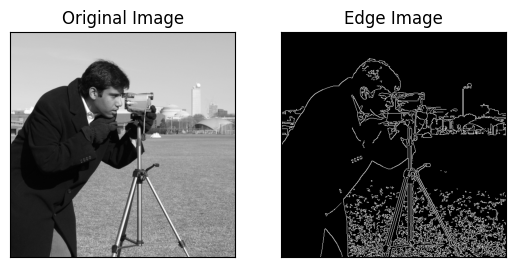

In [2]:
# --- Code from the lab manual ---
img = data.camera()                                  

edges = cv2.Canny(img, 100, 200)

plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(edges, cmap='gray')
plt.title('Edge Image'), plt.xticks([]), plt.yticks([])
plt.show()

## Task 2 — Harris Corner Detection

A **corner** is a point where the image changes in *two* different directions — which makes corners highly distinctive (useful for matching, tracking, camera calibration).



- Large positive `R` → corner
- Large negative `R` → edge
- Small `R` → flat region

Parameters: `blockSize` (window size), `ksize` (Sobel kernel size), `k` (sensitivity, typically 0.04–0.06).

> **Note:** OpenCV uses BGR order, so `(0, 0, 255)` is red.

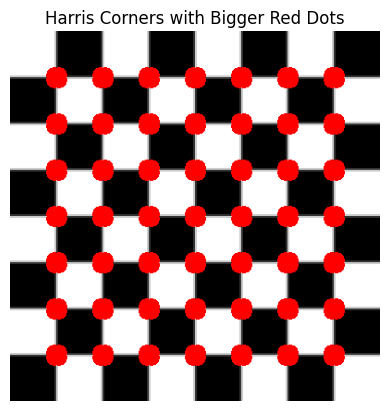

In [3]:
# --- Code from the lab manual ---
board = data.checkerboard()                        
image = cv2.cvtColor(board, cv2.COLOR_GRAY2BGR)
image = cv2.resize(image, (400, 400), interpolation=cv2.INTER_NEAREST)

# Convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
gray = np.float32(gray)

# Harris Corner Detection
harris = cv2.cornerHarris(gray, blockSize=2, ksize=3, k=0.04)
harris = cv2.dilate(harris, None)   # to mark corners more clearly

# Threshold for detecting strong corners
threshold = 0.01 * harris.max()
corner_coords = np.argwhere(harris > threshold)

# Draw larger red dots (radius = 7)
for y, x in corner_coords:
    cv2.circle(image, (x, y), radius=7, color=(0, 0, 255), thickness=-1)  # -1 = filled

# Display
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('Harris Corners with Bigger Red Dots')
plt.axis('off')
plt.show()

## Simple (Global) Binary Thresholding
The most basic segmentation: pick a fixed threshold `T` and turn every pixel above it white, below it black.

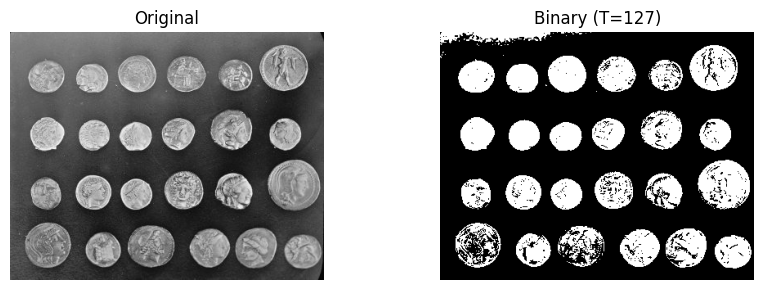

(None, None)

In [4]:
img = data.coins()

T = 127
_, binary = cv2.threshold(img, T, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(9, 3))
plt.subplot(1, 2, 1), plt.imshow(img, cmap='gray'), plt.title('Original'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(binary, cmap='gray'), plt.title(f'Binary (T={T})'), plt.axis('off')
plt.tight_layout(), plt.show()

## Q1 — Otsu's Thresholding (Assessment Task)
Otsu picks `T` **automatically** by maximizing the between-class variance — assumes the histogram has two peaks (foreground + background).

show the original image, its histogram, and the thresholded image.

Otsu threshold T = 107.0


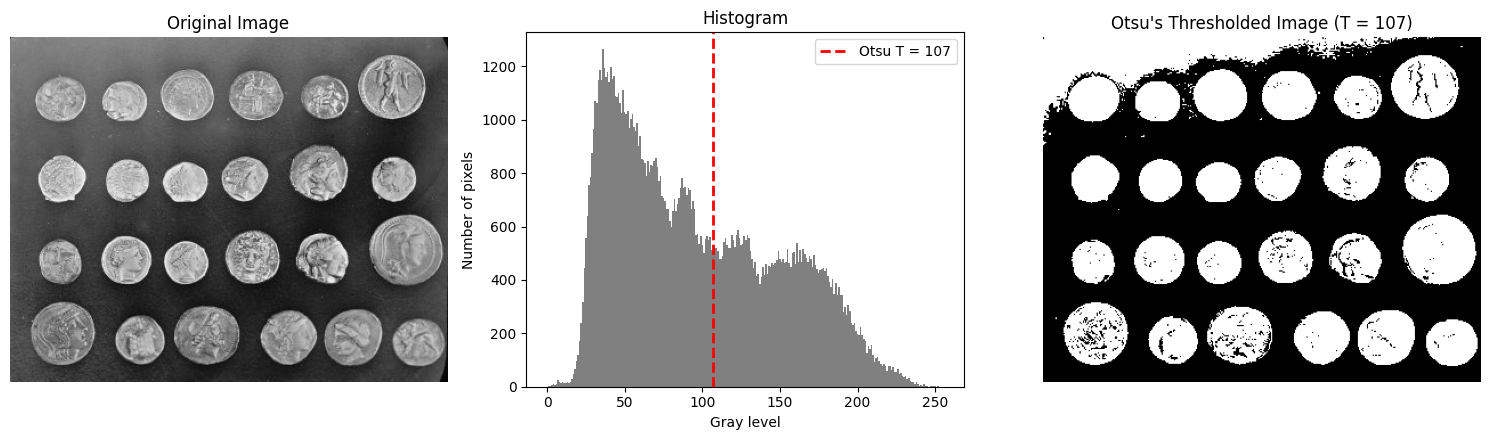

In [5]:
# ---------- Q1: Otsu's Thresholding ----------
img = data.coins()                      # 8-bit grayscale image (coins on a darker background)

# 1. Otsu: threshold value 0 is ignored, cv2 finds the best T automatically
T_otsu, otsu = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Otsu threshold T =", T_otsu)

# 2. Histogram of the image
hist = cv2.calcHist([img], [0], None, [256], [0, 256]).ravel()

# 3. Show: original image, histogram (with the Otsu threshold), thresholded image
plt.figure(figsize=(15, 4.5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray'), plt.title('Original Image'), plt.axis('off')

plt.subplot(1, 3, 2)
plt.bar(range(256), hist, width=1.0, color='gray')
plt.axvline(T_otsu, color='red', linestyle='--', linewidth=2, label=f'Otsu T = {T_otsu:.0f}')
plt.title('Histogram'), plt.xlabel('Gray level'), plt.ylabel('Number of pixels'), plt.legend()

plt.subplot(1, 3, 3)
plt.imshow(otsu, cmap='gray'), plt.title(f"Otsu's Thresholded Image (T = {T_otsu:.0f})"), plt.axis('off')

plt.tight_layout()
plt.show()

### Checking Otsu's threshold manually (and comparing with the fixed T = 127)

Otsu tries every possible `T` and keeps the one with the **largest between-class variance** `σ²_B(T) = w0 · w1 · (μ0 − μ1)²`. Below we compute this ourselves, confirm it matches OpenCV, and compare with the fixed threshold used earlier.

Manual Otsu T : 107
OpenCV Otsu T : 107


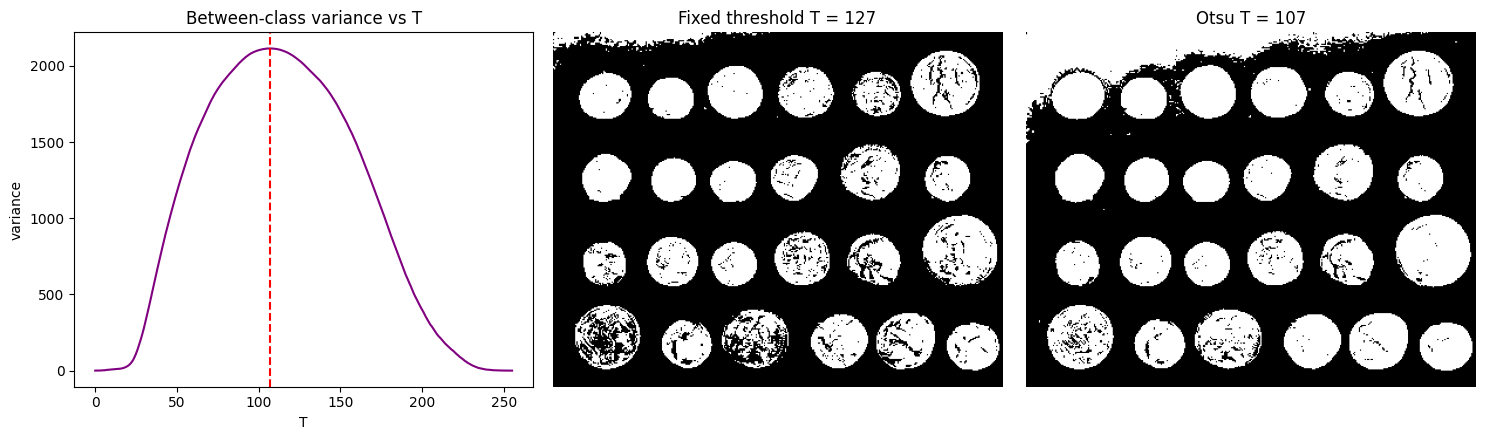

White pixels - fixed T=127: 34469 | Otsu: 45117


In [6]:
# Manual Otsu: maximise the between-class variance over all T
p = hist / hist.sum()                 # probability of each gray level
levels = np.arange(256)
best_T, best_var = 0, -1
variances = np.zeros(256)
for T in range(1, 255):
    w0, w1 = p[:T + 1].sum(), p[T + 1:].sum()
    if w0 == 0 or w1 == 0:
        continue
    mu0 = (levels[:T + 1] * p[:T + 1]).sum() / w0
    mu1 = (levels[T + 1:] * p[T + 1:]).sum() / w1
    variances[T] = w0 * w1 * (mu0 - mu1) ** 2
    if variances[T] > best_var:
        best_T, best_var = T, variances[T]

print("Manual Otsu T :", best_T)
print("OpenCV Otsu T :", int(T_otsu))

# Compare: fixed T=127 vs Otsu
_, fixed = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(15, 4.5))
plt.subplot(1, 3, 1)
plt.plot(variances, color='purple'), plt.axvline(best_T, color='red', linestyle='--')
plt.title('Between-class variance vs T'), plt.xlabel('T'), plt.ylabel('variance')
plt.subplot(1, 3, 2)
plt.imshow(fixed, cmap='gray'), plt.title('Fixed threshold T = 127'), plt.axis('off')
plt.subplot(1, 3, 3)
plt.imshow(otsu, cmap='gray'), plt.title(f"Otsu T = {T_otsu:.0f}"), plt.axis('off')
plt.tight_layout()
plt.show()

print("White pixels - fixed T=127:", int(np.count_nonzero(fixed)), "| Otsu:", int(np.count_nonzero(otsu)))

### Observations (Q1)

* The histogram has **two groups of gray levels**: a large group of dark pixels (the background, around 30-90) and a wider, flatter group of brighter pixels (the coins, around 110-200). Otsu's method assumes this bimodal shape and places the threshold between the two groups. The valley here is shallow because the two groups overlap.
* Otsu chose **T = 107** automatically, without trial and error. My manual implementation (maximising the between-class variance) gives the same value, which confirms how the method works.
* In the thresholded image the coins are **white** (foreground) and most of the background is **black**, so the coins are segmented from the background.
* Compared with the fixed `T = 127` (34,469 white pixels), Otsu's lower threshold (45,117 white pixels) keeps more of the coin surfaces. The fixed value is a guess, while Otsu adapts to the histogram of the image.
* **Limitations:** (1) the bright upper-right part of the background is wrongly turned white, because the lighting is not uniform and one global threshold cannot handle it; (2) dark details on some coins (engravings, shadows) appear as black holes inside the white coins. For uneven illumination, adaptive thresholding (`cv2.adaptiveThreshold`) is a better choice.

---
## Summary table

| Technique | Category | What it finds | OpenCV function |
|---|---|---|---|
| Canny | Edge detection | Thin connected edges | `cv2.Canny` |
| Sobel | Edge detection | Gradient magnitude (thick) | `cv2.Sobel` |
| Laplacian | Edge detection | Zero-crossings (2nd deriv) | `cv2.Laplacian` |
| Harris | Feature extraction | Corners | `cv2.cornerHarris` |
| Shi-Tomasi | Feature extraction | Corners (improved) | `cv2.goodFeaturesToTrack` |
| Simple threshold | Segmentation | Fixed-`T` binary mask | `cv2.threshold` |
| Otsu | Segmentation | Auto bimodal threshold | `cv2.threshold` + `THRESH_OTSU` |
| Adaptive threshold | Segmentation | Local-`T` binary mask | `cv2.adaptiveThreshold` |

**End of notebook.**